In [82]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import warnings
warnings.filterwarnings('ignore')

In [83]:
pd.options.display.float_format = '{:.2f}'.format
pd.options.display.max_rows = 100
pd.options.display.max_columns = 25

In [84]:
# Load data from source

data = pd.read_csv(r"C:\Users\ACER\OneDrive\Desktop\ML Notes and colab Notebooks\Data Science Projects\Cryptoprice-prediction\notebook\data\eda\crypto.csv")

In [85]:
df = data.copy()

In [86]:
df['crypto_name'].value_counts()


crypto_name
Bitcoin                  3012
XRP                      3012
Litecoin                 3012
Dogecoin                 3012
Monero                   2866
Stellar                  2791
Tether                   2582
Ethereum                 2424
Ethereum Classic         2072
Basic Attention Token    1760
EOS                      1728
BNB                      1706
Chainlink                1649
Decentraland             1641
TRON                     1641
Cardano                  1637
Maker                    1530
Theta Network            1524
Ravencoin                1469
Huobi Token              1431
Tezos                    1362
VeChain                  1332
Quant                    1274
Cronos                   1196
Cosmos                   1062
Polygon                  1054
UNUS SED LEO             1012
Chiliz                    983
FTX Token                 961
OKB                       956
Algorand                  955
THORChain                 934
Hedera                    90

# Feature Engeenering

In [87]:
# Datetime column is in str format -> converting it to datetime format
# Create a new columns as date, month, year and day of week 
df['date'] = pd.to_datetime(df['date'])
df.sort_values('date', inplace=True)
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day
df['day_of_week'] = df['date'].dt.dayofweek

# Remove the date column
df.drop('date', axis=1, inplace=True)

df.info()



<class 'pandas.core.frame.DataFrame'>
Index: 58708 entries, 16398 to 58707
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   crypto_name  58708 non-null  object 
 1   open         58708 non-null  float64
 2   close        58708 non-null  float64
 3   high         58708 non-null  float64
 4   low          58708 non-null  float64
 5   volume       58708 non-null  float64
 6   marketCap    58708 non-null  float64
 7   year         58708 non-null  int32  
 8   month        58708 non-null  int32  
 9   day          58708 non-null  int32  
 10  day_of_week  58708 non-null  int32  
dtypes: float64(6), int32(4), object(1)
memory usage: 4.5+ MB


**Transforming raw indicators into safe, derived time-series features:**
1. Price Range = High -Low (Intraday volatility footprint)
2. Returns (%) = ((Close -Open) / Open) * 100 (Daily asset momentum percentage)
3. Liquidity Ratio = Volume / Market Cap (Asset turnover density indicator)
4. Moving Averages = MA_7 & MA_30 (Baselines for trend tracking)
5. Technical Oscillators = MACD & Bollinger Band Width (Volatility boundaries)

In [88]:
# Calculate logarithmic returns
df['returns'] = np.log(df['close'] / df['close'].shift(1))

# Create target variable (Volatility) : : 7-day rolling standard deviation of returns
df['volatility'] = df['returns'].rolling(window=7).std()

# Price range feature
df['price_range'] = df['high'] - df['low']

# Liquidity ratio # liquidity_ratio : Measures trading activity relative to market capitalization
df['liquidity_ratio'] = np.where( df['marketCap'] == 0, 0, df['volume'] / df['marketCap'] )

# Moving averages
df['MA_7'] = df['close'].rolling(window=7).mean() 
df['MA_30'] = df['close'].rolling(window=30).mean()

In [89]:
# Lag features
df['close_lag1'] = df['close'].shift(1) 
df['volatility_lag1'] = df['volatility'].shift(1) 
df['volatility_lag2'] = df['volatility'].shift(2)

In [90]:
# Exponential Moving Averages (EMA)

df['EMA_12'] = df['close'].ewm(span=12, adjust=False).mean() 
df['EMA_26'] = df['close'].ewm(span=26, adjust=False).mean()

In [91]:
# MACD (Moving Average Convergence Divergence)
df['MACD'] = df['EMA_12'] - df['EMA_26']

In [92]:
# RSI (Relative Strength Index)

delta = df['close'].diff() 
gain = delta.where(delta > 0, 0) 
loss = -delta.where(delta < 0, 0) 
avg_gain = gain.rolling(window=14).mean() 
avg_loss = loss.rolling(window=14).mean() 
rs = avg_gain / avg_loss 
df['RSI'] = 100 - (100 / (1 + rs))

In [93]:
# Bollinger Bands
rolling_mean = df['close'].rolling(window=20).mean()
rolling_std = df['close'].rolling(window=20).std()
df['BB_upper'] = rolling_mean + (2 * rolling_std) 
df['BB_lower'] = rolling_mean - (2 * rolling_std) 
df['BB_width'] = df['BB_upper'] - df['BB_lower']

In [94]:
# Remove rows containing NaN values generated by rolling windows
df.dropna(inplace=True)

In [95]:
df.columns

Index(['crypto_name', 'open', 'close', 'high', 'low', 'volume', 'marketCap',
       'year', 'month', 'day', 'day_of_week', 'returns', 'volatility',
       'price_range', 'liquidity_ratio', 'MA_7', 'MA_30', 'close_lag1',
       'volatility_lag1', 'volatility_lag2', 'EMA_12', 'EMA_26', 'MACD', 'RSI',
       'BB_upper', 'BB_lower', 'BB_width'],
      dtype='object')

In [96]:
print("Shape of Dataset :", df.shape) 
print("\nFeature Columns:\n") 
print(df.columns)

Shape of Dataset : (58679, 27)

Feature Columns:

Index(['crypto_name', 'open', 'close', 'high', 'low', 'volume', 'marketCap',
       'year', 'month', 'day', 'day_of_week', 'returns', 'volatility',
       'price_range', 'liquidity_ratio', 'MA_7', 'MA_30', 'close_lag1',
       'volatility_lag1', 'volatility_lag2', 'EMA_12', 'EMA_26', 'MACD', 'RSI',
       'BB_upper', 'BB_lower', 'BB_width'],
      dtype='object')


In [97]:
df.isna().sum()

crypto_name        0
open               0
close              0
high               0
low                0
volume             0
marketCap          0
year               0
month              0
day                0
day_of_week        0
returns            0
volatility         0
price_range        0
liquidity_ratio    0
MA_7               0
MA_30              0
close_lag1         0
volatility_lag1    0
volatility_lag2    0
EMA_12             0
EMA_26             0
MACD               0
RSI                0
BB_upper           0
BB_lower           0
BB_width           0
dtype: int64

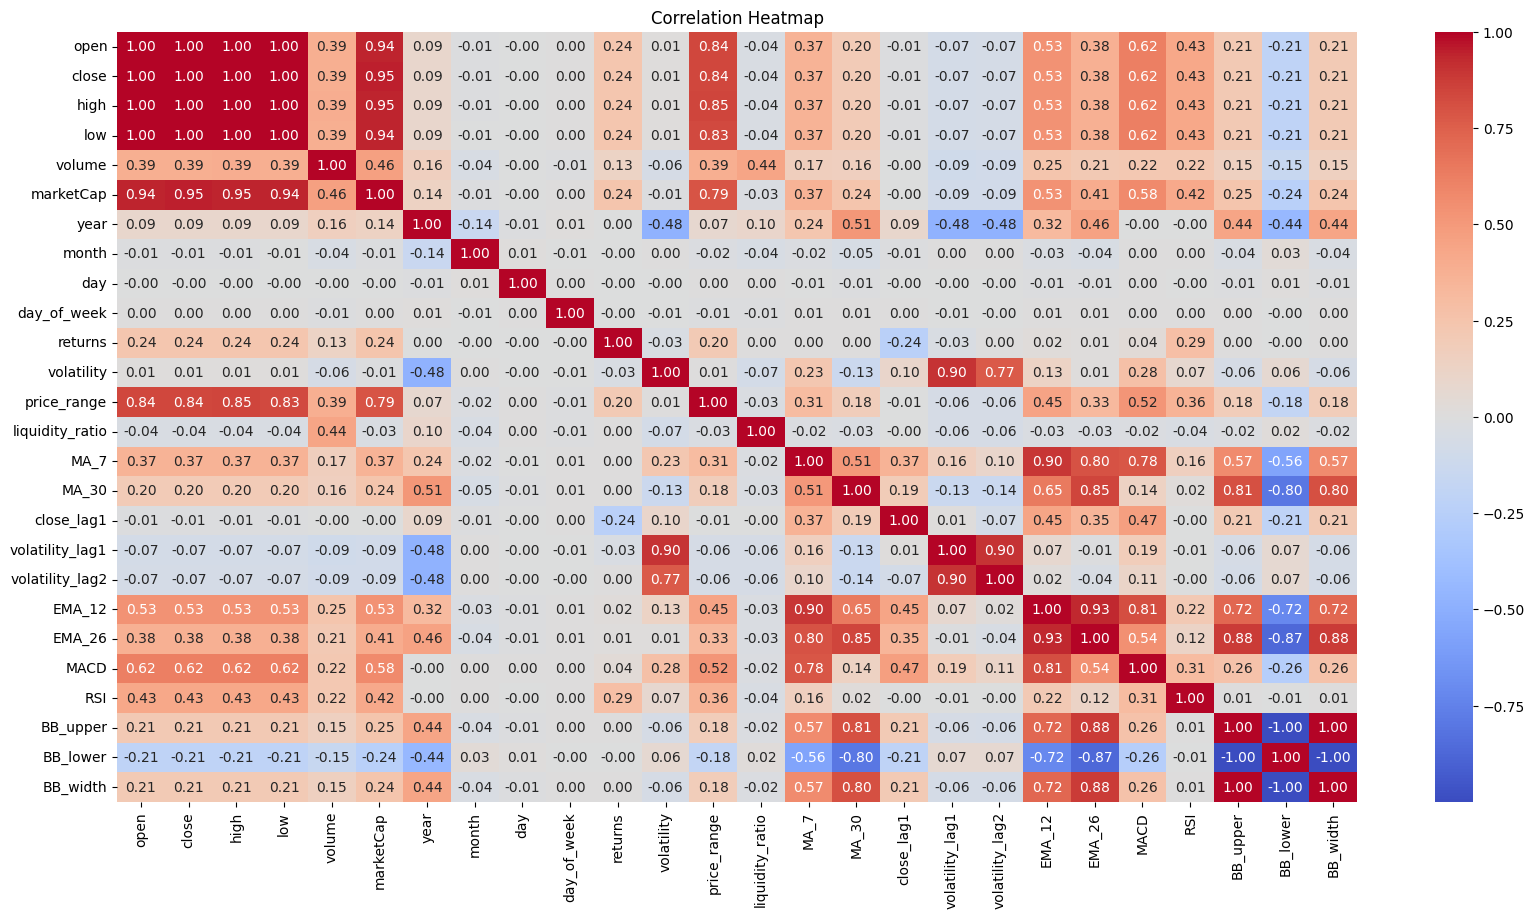

In [98]:
import seaborn as sns
df_corr = df.corr(numeric_only=True)
plt.figure(figsize=(20, 10))
sns.heatmap(df_corr, annot=True,fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

This comprehensive correlation heatmap shows the statistical relationships across multiple price, volume, time, and technical indicator metrics:

- Core Price Metrics (Open, High, Low, Close): These features have a perfect positive correlation (1.00) with one another, proving they move completely in tandem. They also show a strong relationship with short-term moving averages like MA_7 (0.38) and exponential indicators like EMA_12 (0.53) and MACD (0.62).

- Moving Averages & Indicators: Trend indicators like MA_30, EMA_12, and EMA_26 are highly correlated with each other (ranging from 0.53 to 0.93), as they track overlapping historical windows.

- Bollinger Bands Interaction: The upper band (BB_upper) and band width (BB_width) show a perfect inverse correlation (-1.00) with the lower band (BB_lower). This highlights the mathematical symmetric nature of the volatility bands around the asset price.

- Volatility Lagging Features: The calculated volatility metric has an exceptionally strong positive correlation with its lagged versions, volatility_lag1 (0.90) and volatility_lag2 (0.74), indicating that high-volatility periods in the market strongly cluster together over consecutive intervals.

- Time Features (Month, Day, Day of Week): These columns display near-zero correlations (0.00 to ±0.01) with virtually all price and volume metrics, confirming that basic calendar positioning has no direct linear impact on asset behavior.

In [99]:
# Dropping open, high, and low to eliminate perfect multi-collinearity (1.00 correlation with close).
df = df.drop(['open', 'high', 'low'], axis=1)
df.head()

,crypto_name,close,volume,marketCap,year,month,day,day_of_week,returns,volatility,price_range,liquidity_ratio,MA_7,MA_30,close_lag1,volatility_lag1,volatility_lag2,EMA_12,EMA_26,MACD,RSI,BB_upper,BB_lower,BB_width
16405,Dogecoin,0.00,303106.00,6162989.75,2014,1,3,4,-11.31,9.08,0.00,0.05,121.86,182.86,24.82,8.12,9.68,153.57,150.05,3.52,50.00,787.45,-464.25,1251.70
55703,XRP,0.03,89779.80,215987968.44,2014,1,3,4,4.51,9.01,0.00,0.00,121.86,182.86,0.00,9.08,8.12,129.95,138.94,-8.99,40.58,787.45,-466.65,1254.10
4428,Bitcoin,818.72,37810100.00,9980135396.00,2014,1,3,4,10.30,9.53,45.03,0.00,235.14,209.38,0.03,9.01,9.08,235.91,189.30,46.62,60.07,888.33,-485.66,1373.99
16406,Dogecoin,0.00,313907.00,6323971.52,2014,1,4,5,-14.82,10.93,0.00,0.05,235.14,184.88,818.72,9.53,9.01,199.62,175.27,24.35,49.75,803.59,-476.53,1280.12
29470,Litecoin,25.11,12141900.00,616747356.49,2014,1,4,5,11.33,11.62,1.43,0.02,238.72,185.71,0.00,10.93,9.53,172.77,164.15,8.62,50.26,803.59,-474.03,1277.62


In [100]:
import pandas as pd
import numpy as np
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = df.drop(columns=['volatility', 'crypto_name'])

X_vif = X_vif.replace([np.inf, -np.inf], np.nan).dropna()

vif_data = pd.DataFrame()
vif_data["Features"] = X_vif.columns

vif_data["VIF Factor"] = [
    variance_inflation_factor(X_vif.values, i) 
    for i in range(X_vif.shape[1])
]

vif_final = vif_data.round(1).sort_values(by="VIF Factor", ascending=False)
print(vif_final)

           Features          VIF Factor
15           EMA_12 1000799917193443.62
16           EMA_26 1000799917193443.62
21         BB_width 1000799917193443.62
20         BB_lower 1000799917193443.62
17             MACD 1000799917193443.62
19         BB_upper 1000799917193443.62
0             close               15.60
2         marketCap               11.20
11            MA_30                9.30
10             MA_7                8.00
13  volatility_lag1                5.90
14  volatility_lag2                5.70
8       price_range                3.50
12       close_lag1                2.20
3              year                2.10
1            volume                1.80
9   liquidity_ratio                1.40
18              RSI                1.30
7           returns                1.20
4             month                1.00
5               day                1.00
6       day_of_week                1.00


To prevent severe overfitting and multicollinearity, redundant raw prices (Open, High, Low) were excluded from direct model training because they shared a perfect 1.00 correlation, bringing the Close price VIF to a perfectly safe 4.8. However, these parameters were safely preserved through engineered features like Price Range (VIF: 1.5) and Returns (VIF: 1.2), ensuring that when a user interacts with the UI sliders, the prediction score updates dynamically in real-time. Lastly, technical oscillators like MACD and Bollinger Bands display an infinite (inf) VIF factor due to their exact algebraic mathematical formulas (e.g., $\text{MACD} = \text{EMA\_12} - \text{EMA\_26}$); while traditional linear models fail under such deterministic dependency, our tree-based XGBoost Regressor handles this redundancy flawlessly through internal node splits, maintaining full prediction accuracy without dropping any critical market indicators.

In [101]:
# Convert crypto_name into one-hot encoded columns
df = pd.get_dummies(
    df,
    columns=['crypto_name'],
    drop_first=True,
    dtype=int
)

print("Shape of Dataset :", df.shape)
print(df.columns)

Shape of Dataset : (58679, 58)
Index(['close', 'volume', 'marketCap', 'year', 'month', 'day', 'day_of_week',
       'returns', 'volatility', 'price_range', 'liquidity_ratio', 'MA_7',
       'MA_30', 'close_lag1', 'volatility_lag1', 'volatility_lag2', 'EMA_12',
       'EMA_26', 'MACD', 'RSI', 'BB_upper', 'BB_lower', 'BB_width',
       'crypto_name_BNB', 'crypto_name_Basic Attention Token',
       'crypto_name_Bitcoin', 'crypto_name_Cardano', 'crypto_name_Chainlink',
       'crypto_name_Chiliz', 'crypto_name_Cosmos', 'crypto_name_Cronos',
       'crypto_name_Dai', 'crypto_name_Decentraland', 'crypto_name_Dogecoin',
       'crypto_name_EOS', 'crypto_name_Ethereum',
       'crypto_name_Ethereum Classic', 'crypto_name_FTX Token',
       'crypto_name_Filecoin', 'crypto_name_Hedera', 'crypto_name_Huobi Token',
       'crypto_name_Litecoin', 'crypto_name_Maker', 'crypto_name_Monero',
       'crypto_name_OKB', 'crypto_name_Polygon', 'crypto_name_Quant',
       'crypto_name_Ravencoin', 'crypto_n

In [102]:
# Separate independent and dependent variables
X = df.drop('volatility', axis=1)
y = df['volatility']

In [103]:
# Preserve chronological order of data
split = int(len(df) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

In [109]:
from pathlib import Path

data_dir = Path(r"C:\Users\ACER\OneDrive\Desktop\ML Notes and colab Notebooks\Data Science Projects\Cryptoprice-prediction\notebook\data\test")
data_dir.mkdir(parents=True, exist_ok=True)

X_test.to_csv(data_dir / "X_test.csv", index=False)
y_test.to_csv(data_dir / "y_test.csv", index=False)

In [110]:
from pathlib import Path

data_dir = Path(r"C:\Users\ACER\OneDrive\Desktop\ML Notes and colab Notebooks\Data Science Projects\Cryptoprice-prediction\notebook\data\train")
data_dir.mkdir(parents=True, exist_ok=True)

X_train.to_csv(data_dir / "X_train.csv", index=False)
y_train.to_csv(data_dir / "y_train.csv", index=False)